# Laboratorio de señales

Registro, preprocesamiento y análisis de una señal de electrocardiograma (ECG) adquirida con un módulo AD8232 y una placa Arduino UNO.

## Consigna 1

La señal fue registrada en un archivo CSV, con una columna para el número de muestra y otra para la amplitud; es decir, $n$ en una columna y $x[n]$ en la otra.

Otros formatos utilizados con el mismo fin son `.txt` y `.json`, también útiles para analizar estas señales en Python o MATLAB.

En Europa, un formato muy utilizado es el *EDF/EDF+, orientado al registro multicanal y adaptado para almacenar señales biomédicas: guarda la señal cruda junto con los datos de muestreo y de calibración.

Los datos también pueden obtenerse en formato papel, mediante una técnica de impresión en papel milimetrado termosensible. La señal se capta con electrodos, se amplifica y filtra con un módulo analógico y luego se digitaliza; con esos datos, el cabezal va dibujando la señal a medida que el papel milimetrado avanza.

## Consigna 2

*(Consigna pendiente de completar — no había contenido en el documento original.)*

## Consigna 3

### Inciso a

La sensibilidad analógica del sistema no depende solo del módulo AD8232: este amplifica la señal (con una ganancia fija $G = 100\ \text{V/V}$) pero no la convierte a digital. La resolución del sistema de adquisición está dada por:

$$\text{Resolución} = \frac{V_{ref}}{2^{N} \cdot G}$$

donde $N$ es la cantidad de bits del conversor analógico-digital (depende de la placa utilizada) y $V_{ref}$ es la tensión de referencia.

En este trabajo se usó una placa Arduino UNO, con $V_{ref} = 3{,}3\ \text{V}$ y un conversor de **10 bits** ($2^{10} = 1024$ niveles). Con la ganancia del AD8232 ($G = 100$):

$$\text{Resolución} = \frac{3{,}3\ \text{V}}{1024 \times 100} \approx 32{,}22\ \mu\text{V por nivel}$$

### Inciso b

Los electrodos utilizados corresponden a la configuración de Mason-Likar, generalmente usada en estudios de actividad física porque fija los cables al torso y evita que se muevan mientras el paciente se ejercita. En estudios en reposo, en cambio, se prefiere la colocación clásica en los segmentos distales (muñecas y tobillos), ya que ubicar los electrodos en el torso altera el eje eléctrico y puede simular falsos infartos o enmascarar isquemias.

Los electrodos en manos y pies permiten ver el corazón en el plano frontal. Para verlo en las tres dimensiones se necesita, además, el plano horizontal (electrodos precordiales, en el pecho). Con los electrodos de los miembros se forman las tres derivaciones bipolares clásicas (triángulo de Einthoven):

- I = LA − RA
- II = LL − RA
- III = LL − LA

Estas tres derivaciones aproximan al tronco como un volumen conductor con el corazón en su centro. Combinando las mismas señales se obtienen las derivaciones aumentadas aVR, aVL y aVF; el terminal central de Wilson sirve de referencia para las derivaciones precordiales.

### Inciso c

Las derivaciones de los miembros que faltan son aVR, aVL y aVF, que son unipolares: en cada una, el electrodo de la extremidad correspondiente es el polo positivo, y el negativo es el promedio de los otros dos. Junto con I, II y III completan el plano frontal, con seis vistas del corazón separadas cada 30°. Las derivaciones que faltan por completar los doce registros clásicos son las precordiales V1 a V6, que registran el plano horizontal del corazón.

Los médicos usan el conjunto de las doce derivaciones para evaluar distintas patologías:

- Localizar un infarto o isquemia, porque cada grupo de derivaciones observa una pared distinta del corazón:
  - Anterior: V1–V4
  - Lateral: I, aVL, V5–V6
  - Inferior: II, III, aVF
  - Imagen en espejo (pared posterior): V1–V2
- Detectar hipertrofia o sobrecarga de cámaras, por la amplitud de las ondas en las distintas derivaciones.
- Identificar bloqueos de rama y trastornos de conducción (por ejemplo, el bloqueo de rama derecha se reconoce por su morfología característica en V1 y V6).
- Ubicar el origen de una arritmia y distinguir una taquicardia supraventricular de una ventricular, por la morfología y el eje del QRS.

## Consigna 4

La señal presenta, a simple vista, dos tipos de ruido que deberán eliminarse en la etapa de preprocesamiento.

Figura 1 — Señal pre actividad física

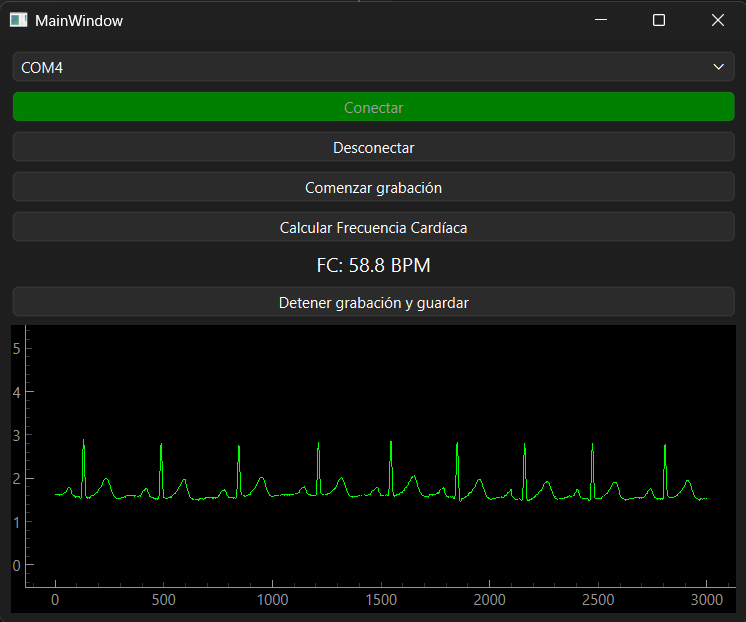

Figura 2 — Señal post actividad física

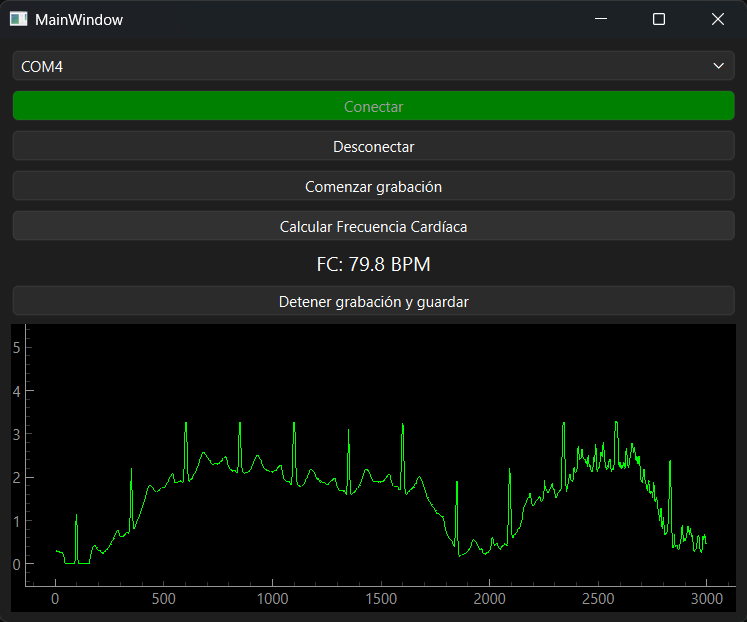

En la señal post actividad física se observa ruido de deriva de línea de base, visible como las "montañas" sobre las que queda montada la señal, sobre todo en la Figura 2. Este ruido puede deberse a movimientos corporales y a la respiración, cuya frecuencia aumenta después del ejercicio; por eso en la señal pre actividad física no se nota con la misma intensidad.

El otro ruido, presente en ambas señales, es ruido de línea, originado por la actividad electromagnética de la red eléctrica y de los dispositivos utilizados durante la medición.

## Referencias

- [EDF+ Specification](https://www.edfplus.info/specs/edfplus.html)
- [Arduino — analogRead()](https://docs.arduino.cc/language-reference/en/functions/analog-io/analogRead/)
- [AD8232 Datasheet](https://www.alldatasheet.com/datasheet-pdf/view/544648/AD/AD8232.html)
- [Lab Protocols — ECG (Universidad Carolina, Praga)](https://fyziologie.lf1.cuni.cz/file/6007/lab-protocols-ecg.pdf)